# Predicting Wages with the 2020 American Community Survey
### OLS, forward stepwise, Lasso, Ridge and random forest

**Question.** How well can individual characteristics predict a worker's annual wage and salary
income, and does a flexible machine-learning model beat a well-specified linear one?

**Data.** The 2020 ACS 1-year sample from IPUMS USA, requested programmatically through the IPUMS
API. Nothing is downloaded by hand.

**Roadmap.**
1. Request the extract through the IPUMS API.
2. Inspect the raw codes: employment status, class of worker, special values of the wage variable.
3. Build the sample one documented filter at a time, then recode the raw IPUMS codes into
   interpretable groups.
4. Explore how wages vary with education, age, sex, occupation and hours.
5. Fit five models on the same training data, compare them on held-out data, and interpret.

**Headline results** (875,856 eligible workers; 200,000 used for modelling):
- The **random forest** predicts best, with a test R² of **0.595** against **0.558** for OLS,
  Lasso and Ridge. Its typical (median) prediction is within about 30% of the actual wage.
- **Lasso and Ridge do not improve on OLS.** With far more observations than features, CV picks
  near-zero penalties. Forward stepwise keeps 9 of 13 feature groups and gives up only 0.005 of R².
- **Hours, weeks worked, education and occupation** carry most of the predictive power. Holding
  them fixed, a bachelor's degree is worth about +39% over not finishing high school, and women
  earn about 17% less than comparable men.

## 1. Setup

In [1]:
import os
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LassoCV, LinearRegression, RidgeCV
from sklearn.model_selection import KFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW_FILE = ROOT / "data" / "raw" / "acs2020.parquet"
FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
SEED = 42

pd.set_option("display.float_format", "{:,.3f}".format)

In [2]:
import matplotlib.pyplot as plt

# Plot style: light surface, recessive grid, one blue for single-series charts.
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, INK_2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": GRID, "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.axisbelow": True, "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "xtick.color": INK_2, "ytick.color": INK_2, "font.size": 10,
    "figure.dpi": 110, "savefig.dpi": 160, "savefig.bbox": "tight",
})

## 2. Data: request an extract through the IPUMS API

The extract contains the 2020 ACS 1-year sample (`us2020a`) and only the variables used below.
For 2020, IPUMS recommends the **experimental person weight** `EXPWTP` instead of `PERWT`, because
the pandemic disrupted data collection. The Census Bureau built these weights to correct the
resulting non-response bias.

**Credentials.** Create a free API key at <https://account.ipums.org/api_keys> and put it in a
`.env` file at the repo root as `IPUMS_API_KEY=...`. The extract takes a few minutes to build, and
the result is cached to `data/raw/`. IPUMS terms prohibit redistributing the microdata, so the
data are not committed.

In [3]:
VARIABLES = [
    "AGE", "SEX", "MARST", "RACE", "HISPAN", "CITIZEN",          # demographics
    "EDUCD", "DEGFIELD", "SCHOOL",                                # education
    "EMPSTAT", "CLASSWKR", "OCC", "IND", "UHRSWORK", "WKSWORK1",  # work
    "PWSTATE2", "INCWAGE", "EXPWTP",                              # place of work, outcome, weight
]


def download_acs(path: Path = RAW_FILE) -> pd.DataFrame:
    from dotenv import load_dotenv
    from ipumspy import IpumsApiClient, MicrodataExtract, readers

    load_dotenv(ROOT / ".env")
    client = IpumsApiClient(os.environ["IPUMS_API_KEY"])
    extract = MicrodataExtract(collection="usa", samples=["us2020a"], variables=VARIABLES,
                               description="ML & Econometrics: 2020 ACS wage prediction")
    client.submit_extract(extract)
    client.wait_for_extract(extract)

    out_dir = path.parent / "ipums"
    out_dir.mkdir(parents=True, exist_ok=True)
    client.download_extract(extract, download_dir=out_dir)
    ddi = readers.read_ipums_ddi(next(out_dir.glob(f"*{extract.extract_id:05d}.xml")))
    df = readers.read_microdata(ddi, out_dir / ddi.file_description.filename)[VARIABLES]
    df.to_parquet(path, index=False)
    return df


raw = pd.read_parquet(RAW_FILE) if RAW_FILE.exists() else download_acs()
print(f"{len(raw):,} person records, {raw.shape[1]} variables")
raw.head()

2,641,054 person records, 18 variables


,AGE,SEX,MARST,RACE,HISPAN,CITIZEN,EDUCD,DEGFIELD,SCHOOL,EMPSTAT,CLASSWKR,OCC,IND,UHRSWORK,WKSWORK1,PWSTATE2,INCWAGE,EXPWTP
0,68,1,2,1,0,0,63,0,1,3,0,0,0,0,0,0,0,53.000
1,18,2,6,2,0,0,65,0,2,3,2,4110,8680,20,24,0,4800,39.000
2,35,2,6,1,0,0,63,0,1,3,0,0,0,0,0,0,0,17.000
3,46,2,2,8,0,0,65,0,1,3,0,0,0,0,0,0,0,74.000
4,79,2,6,1,0,0,114,23,1,3,0,0,0,0,0,0,0,188.000


## 3. First look at the raw data

IPUMS stores every variable as a numeric **code**. The codes have to be read against the codebook
before any of them can be used. Two variables decide who belongs in a wage model: employment status
and class of worker.

In [4]:
EMPSTAT = {0: "N/A (under 16)", 1: "Employed", 2: "Unemployed", 3: "Not in labor force"}
CLASSWKR = {0: "N/A (not working)", 1: "Self-employed", 2: "Works for wages"}
pd.concat({
    "Employment status": raw["EMPSTAT"].map(EMPSTAT).value_counts(),
    "Class of worker": raw["CLASSWKR"].map(CLASSWKR).value_counts(),
}).rename("people").to_frame().assign(share=lambda d: (d["people"] / len(raw) * 100).round(1))

people  share
Employment status Employed            1194039 45.200
                  Not in labor force   932165 35.300
                  N/A (under 16)       440438 16.700
                  Unemployed            74412  2.800
Class of worker   Works for wages     1384869 52.400
                  N/A (not working)   1091286 41.300
                  Self-employed        164899  6.200

In [5]:
inc = raw["INCWAGE"]
pd.Series({
    "999999 (N/A: under 16 or not asked)": (inc == 999_999).sum(),
    "999998 (missing)": (inc == 999_998).sum(),
    "0 (no wage income)": (inc == 0).sum(),
    "1 to 999": inc.between(1, 999).sum(),
    "1,000 or more": inc.between(1_000, 999_997).sum(),
}, name="people").to_frame().assign(share=lambda d: (d["people"] / len(raw) * 100).round(1))

,people,share
999999 (N/A: under 16 or not asked),440438,16.700
999998 (missing),0,0.000
0 (no wage income),919870,34.800
1 to 999,28676,1.100
"1,000 or more",1252070,47.400


**Interpretation.**
- `INCWAGE` uses **999999 as a "not applicable" code**. Treated as a number, it would be read as a
  wage of almost $1M for every child in the file, which is why the special codes must be removed
  before any arithmetic.
- **More than a third of the records have zero wage income**: children, retirees, students, the
  unemployed and people outside the labor force. A wage model is meant to describe *workers*, so
  the sample has to be restricted to people for whom a wage is meaningful.

## 4. Building the sample, step by step

In [6]:
steps = [("2020 ACS person records", len(raw))]


def keep(df, mask, label):
    out = df[mask]
    steps.append((label, len(out)))
    print(f"{label}: {len(df) - len(out):,} removed, {len(out):,} remain")
    return out


df = keep(raw, raw["AGE"].between(18, 64), "Aged 18-64")
df = keep(df, df["EMPSTAT"] == 1, "Employed")

Aged 18-64: 1,070,980 removed, 1,570,074 remain
Employed: 486,015 removed, 1,084,059 remain


**Working age (18–64) and employed.** The conventional working-age range excludes most students
and retirees. Wages are only observed for people who work, so the unemployed and those outside the
labor force are removed.

### 4.1 Wage earners only: why the self-employed are excluded

In [7]:
pd.DataFrame({
    "people": df["CLASSWKR"].map(CLASSWKR).value_counts(),
    "% with zero wage income": df.groupby(df["CLASSWKR"].map(CLASSWKR))["INCWAGE"].apply(lambda s: (s == 0).mean() * 100),
}).round(2)

,people,% with zero wage income
CLASSWKR,,
Self-employed,101784,52.080
Works for wages,982275,0.010


Over half of the self-employed report **zero** wage income, against almost none of the wage
earners. Their earnings are recorded as business income (`INCBUS00`), not `INCWAGE`. Keeping them
would add a large group whose "wage" is an accounting artifact, and a model could "predict" it
from the class-of-worker code alone. The original analysis made this mistake: the self-employed
dummy dominated the feature importance with a score of 0.78. Restricting to wage and salary
earners removes the artifact.

In [8]:
df = keep(df, df["CLASSWKR"] == 2, "Works for wages (excludes self-employed)")
df = keep(df, df["SCHOOL"] == 1, "Not enrolled in school")

Works for wages (excludes self-employed): 101,784 removed, 982,275 remain
Not enrolled in school: 101,963 removed, 880,312 remain


**Not enrolled in school.** Students who work typically hold part-time or temporary jobs whose pay
reflects their schooling status, not their characteristics as workers.

### 4.2 Valid wages and labor supply

In [9]:
low = df[df["INCWAGE"].between(1, 999)]
print(f"Workers earning $1-$999 in the year: {len(low):,} ({len(low) / len(df):.1%})")
print(f"Their median implied hourly wage: ${(low['INCWAGE'] / (low['UHRSWORK'] * low['WKSWORK1'])).median():.2f}")
print(f"Zero usual hours: {(df['UHRSWORK'] == 0).sum():,}   Zero weeks worked: {(df['WKSWORK1'] == 0).sum():,}")

Workers earning $1-$999 in the year: 4,351 (0.5%)
Their median implied hourly wage: $5.62
Zero usual hours: 0   Zero weeks worked: 0


About 4,400 employed wage earners (0.5%) report less than $1,000 for the whole year. Their
median implied hourly wage is $5.62, below the federal minimum of $7.25, which points to
misreported hours, weeks or income, or very marginal jobs. A $1,000 floor removes them. No one
left reports zero hours or weeks, because the employment filter has already done that work.

In [10]:
df = keep(df, df["INCWAGE"].between(1_000, 999_997) & (df["UHRSWORK"] > 0) & (df["WKSWORK1"] > 0),
          "Wage income >= $1,000, positive hours and weeks")

Wage income >= $1,000, positive hours and weeks: 4,456 removed, 875,856 remain


### 4.3 Top-coding

To protect confidentiality, IPUMS replaces the highest wages in each state with the state's top
value. The cap therefore differs from state to state:

In [11]:
state_cap = df.groupby("PWSTATE2")["INCWAGE"].max()
print(f"State top codes range from ${state_cap.min():,.0f} to ${state_cap.max():,.0f} "
      f"(median ${state_cap.median():,.0f})")
print(f"Share of workers at their state's top code: {(df['INCWAGE'] == df['PWSTATE2'].map(state_cap)).mean():.2%}")

State top codes range from $200,000 to $743,000 (median $517,000)
Share of workers at their state's top code: 0.13%


Only 0.13% of workers sit at the cap, so top-coding barely affects average errors. It does
mean that **no model can predict very high earners exactly**: their recorded wage is a ceiling,
not their true wage. Modelling the log of wages also limits the influence of these observations.

### 4.4 Recode raw IPUMS codes into interpretable features

Raw IPUMS codes cannot be used directly. `EDUCD`, for example, has 25 detailed codes whose
numeric values are arbitrary, and `OCC` has more than 500 occupation codes. Each is collapsed into
standard groups. The crosswalk tables below show exactly what was merged.

In [12]:
TARGET, WEIGHT = "log_wage", "EXPWTP"
NUMERIC = ["age", "age_sq", "log_hours", "log_weeks"]
CATEGORICAL = ["sex", "marital", "race", "hispanic", "nativity", "education",
               "degree_field", "occupation", "industry", "work_state"]

EDUCATION = [(61, "Less than high school"), (64, "High school / GED"), (71, "Some college"),
             (81, "Associate"), (101, "Bachelor's"), (114, "Master's"), (115, "Professional"),
             (116, "Doctorate")]
OCCUPATION = [  # 2018 ACS occupation codes -> SOC major groups (upper code of each range)
    (440, "Management"), (960, "Business & financial"), (1240, "Computer & math"),
    (1560, "Architecture & engineering"), (1980, "Science"), (2060, "Community & social service"),
    (2180, "Legal"), (2555, "Education"), (2920, "Arts & media"), (3550, "Healthcare practitioners"),
    (3655, "Healthcare support"), (3960, "Protective service"), (4160, "Food preparation"),
    (4255, "Building & grounds"), (4655, "Personal care"), (4965, "Sales"), (5940, "Office & admin"),
    (6130, "Farming & fishing"), (6950, "Construction & extraction"), (7640, "Installation & repair"),
    (8990, "Production"), (9760, "Transportation"), (9920, "Military")]
INDUSTRY = [  # 2018 ACS industry codes -> sectors
    (290, "Agriculture"), (490, "Mining"), (690, "Utilities"), (770, "Construction"),
    (3990, "Manufacturing"), (4590, "Wholesale"), (5790, "Retail"), (6390, "Transportation"),
    (6780, "Information"), (7190, "Finance & real estate"), (7790, "Professional services"),
    (8470, "Education & health"), (8690, "Leisure & hospitality"), (9290, "Other services"),
    (9590, "Public administration"), (9920, "Military")]


def bucket(codes, table):
    return pd.cut(codes, [-np.inf] + [hi for hi, _ in table], labels=[lab for _, lab in table]).astype(str)


sample = pd.DataFrame({
    "wage": df["INCWAGE"],
    TARGET: np.log(df["INCWAGE"]),
    WEIGHT: df["EXPWTP"],
    "age": df["AGE"],
    "age_sq": df["AGE"] ** 2 / 100,
    "hours": df["UHRSWORK"],
    "weeks": df["WKSWORK1"],
    "log_hours": np.log(df["UHRSWORK"]),
    "log_weeks": np.log(df["WKSWORK1"]),
    "sex": df["SEX"].map({1: "Male", 2: "Female"}),
    "marital": df["MARST"].map({1: "Married", 2: "Married", 3: "Previously married",
                                4: "Previously married", 5: "Previously married", 6: "Never married"}),
    "race": df["RACE"].map({1: "White", 2: "Black", 3: "American Indian / Alaska Native",
                            4: "Asian", 5: "Asian", 6: "Asian"}).fillna("Other / multiple"),
    "hispanic": np.where(df["HISPAN"] > 0, "Hispanic", "Not Hispanic"),
    "nativity": df["CITIZEN"].map({0: "US-born", 1: "Born abroad to US parents",
                                   2: "Naturalized citizen", 3: "Not a citizen"}),
    "education": bucket(df["EDUCD"], EDUCATION),
    "degree_field": df["DEGFIELD"].astype(str),
    "occupation": bucket(df["OCC"], OCCUPATION),
    "industry": bucket(df["IND"], INDUSTRY),
    "work_state": df["PWSTATE2"].astype(str),
}).reset_index(drop=True)

# Crosswalk check: which detailed EDUCD codes ended up in each education group.
df.assign(education=bucket(df["EDUCD"], EDUCATION)).groupby("education").agg(
    EDUCD_codes=("EDUCD", lambda s: ", ".join(map(str, sorted(s.unique())))), people=("EDUCD", "size")
).loc[[lab for _, lab in EDUCATION]]

,EDUCD_codes,people
education,,
Less than high school,"2, 11, 12, 14, 15, 16, 17, 22, 23, 25, 26, 30,...",55631
High school / GED,"63, 64",213108
Some college,"65, 71",164208
Associate,81,83451
Bachelor's,101,220588
Master's,114,100889
Professional,115,21140
Doctorate,116,16841


In [13]:
print("Missing values after recoding:", int(sample.isna().sum().sum()))
print("Unmapped categories ('nan'):", int((sample[CATEGORICAL] == "nan").sum().sum()))
sample[CATEGORICAL].nunique().rename("categories").to_frame().T

Missing values after recoding: 0
Unmapped categories ('nan'): 0


,sex,marital,race,hispanic,nativity,education,degree_field,occupation,industry,work_state
categories,2,3,5,2,4,8,38,23,16,60


Every code maps to a group, with no gaps in the crosswalks, and there are no missing values,
because the filters in 4.1–4.2 already removed the "N/A" codes. The model sees 10 categorical
features with 2 to 60 levels each, plus four numeric features. The 60 work-location levels are the
50 states, DC and codes for work outside the states.

Why these transformations:
- **Log wage as the target.** Wages are right-skewed, and in logs a coefficient reads as an
  approximate percentage difference.
- **Log hours and log weeks.** Annual wage = hourly rate × hours × weeks, so in logs the two
  labor-supply terms enter additively.
- **Age and age².** The Mincer earnings profile rises with experience and then flattens.

In [14]:
sample_log = pd.DataFrame(steps, columns=["step", "people"]).set_index("step")
sample_log["removed"] = -sample_log["people"].diff()
sample_log.map(lambda v: "" if pd.isna(v) else f"{v:,.0f}")

,people,removed
step,,
2020 ACS person records,"2,641,054",
Aged 18-64,"1,570,074","1,070,980"
Employed,"1,084,059","486,015"
Works for wages (excludes self-employed),"982,275","101,784"
Not enrolled in school,"880,312","101,963"
"Wage income >= $1,000, positive hours and weeks","875,856","4,456"


The sample keeps 875,856 of 2.6 million records, a third of the file. The original version of this
analysis kept only 3,092 people. A filter on `VETDISAB != 0` silently restricted it to veterans,
because 0 is the "not a veteran" code.

## 5. Exploratory analysis

### 5.1 Summary statistics (weighted)

In [15]:
def wmean(x, w):
    return np.average(x, weights=w)


w = sample[WEIGHT]
cols = ["wage", "age", "hours", "weeks"]
numeric_summary = pd.DataFrame({
    "weighted mean": [wmean(sample[c], w) for c in cols],
    "std": sample[cols].std().values,
    "p10": sample[cols].quantile(0.10).values,
    "median": sample[cols].median().values,
    "p90": sample[cols].quantile(0.90).values,
}, index=["Annual wage income ($)", "Age", "Usual hours per week", "Weeks worked"])
print(f"{len(sample):,} workers representing {w.sum() / 1e6:,.1f} million people")
numeric_summary.map("{:,.0f}".format)

875,856 workers representing 116.2 million people


,weighted mean,std,p10,median,p90
Annual wage income ($),"61,068","68,602","14,000","47,000","120,000"
Age,41,12,26,43,60
Usual hours per week,41,10,30,40,50
Weeks worked,49,10,42,52,52


In [16]:
def shares(col):
    s = sample.groupby(col)[WEIGHT].sum()
    return (100 * s / s.sum()).sort_values(ascending=False)


composition = pd.concat({c: shares(c) for c in ["sex", "education", "race", "nativity"]})
composition.rename("% of workers").to_frame().map("{:.1f}".format)

% of workers
sex       Male                                    52.7
          Female                                  47.3
education Bachelor's                              24.8
          High school / GED                       24.7
          Some college                            19.2
          Master's                                10.8
          Associate                                9.1
          Less than high school                    7.3
          Professional                             2.3
          Doctorate                                1.8
race      White                                   63.7
          Other / multiple                        17.3
          Black                                   11.6
          Asian                                    6.5
          American Indian / Alaska Native          0.9
nativity  US-born                                 82.0
          Naturalized citizen                      8.8
          Not a citizen                            8.0
          Born abroad to US parents                1.2

- **The typical worker** is in their early 40s, works 40 hours a week and works all 52 weeks.
- **Wages are dispersed.** The mean is $61k against a median of $47k, and the 10th and 90th
  percentiles ($14k and $120k) differ almost nine-fold. The bottom of the distribution is mostly
  part-time or part-year work.
- **Composition.** 53% are men. About 40% hold at least a bachelor's degree, and 18% were born
  abroad. These shares use the person weights, so they describe the 116 million workers in the
  population, not just the survey respondents.

### 5.2 Distribution of the outcome

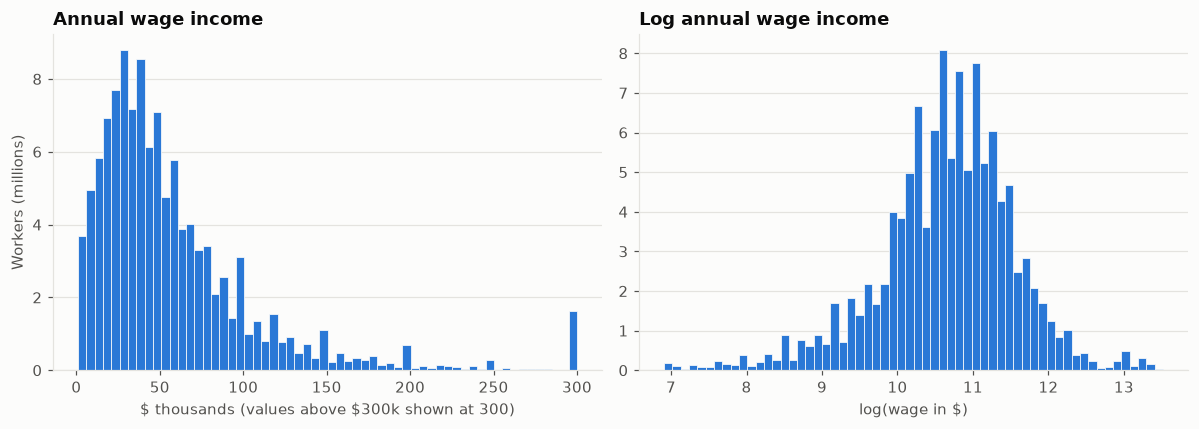

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(sample["wage"].clip(upper=300_000) / 1_000, bins=60, weights=w / 1e6, color=BLUE,
             edgecolor="#fcfcfb", linewidth=0.5)
axes[0].set(title="Annual wage income", xlabel=r"\$ thousands (values above \$300k shown at 300)",
            ylabel="Workers (millions)")
axes[1].hist(sample[TARGET], bins=60, weights=w / 1e6, color=BLUE, edgecolor="#fcfcfb", linewidth=0.5)
axes[1].set(title="Log annual wage income", xlabel=r"log(wage in \$)")
for ax in axes:
    ax.grid(axis="x", visible=False)
fig.tight_layout()
fig.savefig(FIG_DIR / "wage_distribution.png")
plt.show()

- **Dollars:** strongly right-skewed. The mean ($61k) is well above the median ($47k), and the bar
  at 300 collects everyone above $300k. Least squares on dollar wages would be dominated by these
  high earners.
- **Logs:** much closer to symmetric, so log wage is a better-behaved target. The left tail comes
  from part-year and part-time workers, whom the hours and weeks features should explain.
- **The spikes** reflect *heaping*: respondents round their pay to values like $40,000 or $50,000.

### 5.3 Wages by education

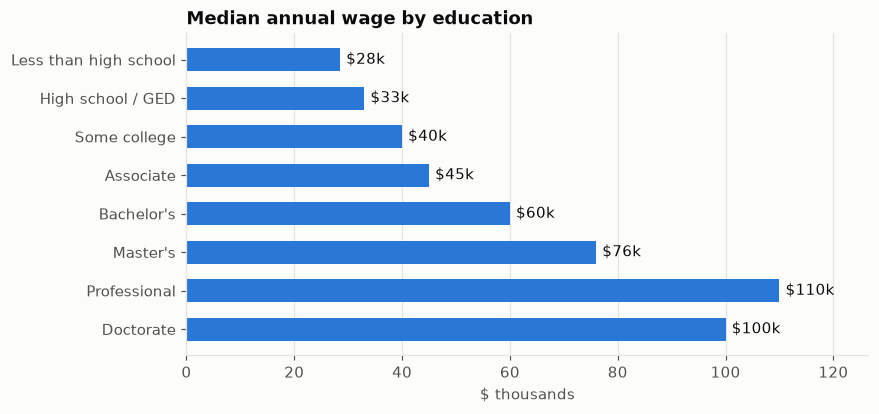

In [18]:
edu_order = [lab for _, lab in EDUCATION]
by_edu = sample.groupby("education").apply(
    lambda g: pd.Series({"median wage": g["wage"].median(), "mean log wage": wmean(g[TARGET], g[WEIGHT])}),
    include_groups=False).loc[edu_order]

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.barh(by_edu.index[::-1], by_edu["median wage"][::-1] / 1000, color=BLUE, height=0.6)
for y, v in enumerate(by_edu["median wage"][::-1] / 1000):
    ax.annotate(f"${v:,.0f}k", (v, y), xytext=(4, 0), textcoords="offset points", va="center", color=INK)
ax.set(title="Median annual wage by education", xlabel=r"\$ thousands", xlim=(0, by_edu["median wage"].max() / 1000 * 1.15))
ax.grid(axis="y", visible=False)
fig.savefig(FIG_DIR / "wage_by_education.png")
plt.show()

Median wages rise at every step of education: from $28k without a high-school diploma to $60k
with a bachelor's degree, more than double, and $76k with a master's. Professional degrees
(medicine, law) earn more than doctorates. These raw gaps overstate the return to education,
because more educated workers also work more hours and in better-paid occupations. The regression
in Section 7 separates these channels.

### 5.4 The age-earnings profile, by sex

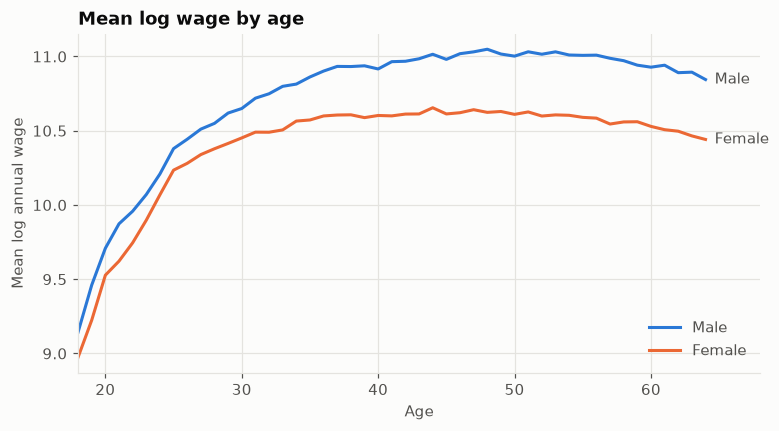

Raw gap in mean log wage, women vs. men: -0.307 log points (-26.4%)


In [19]:
by_age = sample.groupby(["age", "sex"]).apply(lambda g: wmean(g[TARGET], g[WEIGHT]), include_groups=False).unstack()

fig, ax = plt.subplots(figsize=(8, 4))
for sex, color in [("Male", BLUE), ("Female", ORANGE)]:
    ax.plot(by_age.index, by_age[sex], color=color, lw=2, label=sex)
    ax.annotate(sex, (by_age.index[-1], by_age[sex].iloc[-1]), xytext=(6, 0), textcoords="offset points",
                va="center", color=INK_2)
ax.set(title="Mean log wage by age", xlabel="Age", ylabel="Mean log annual wage", xlim=(18, 68))
ax.legend(frameon=False, labelcolor=INK_2, loc="lower right")
fig.savefig(FIG_DIR / "wage_age_profile.png")
plt.show()

raw_gap = wmean(sample.loc[sample["sex"] == "Female", TARGET], sample.loc[sample["sex"] == "Female", WEIGHT]) - \
          wmean(sample.loc[sample["sex"] == "Male", TARGET], sample.loc[sample["sex"] == "Male", WEIGHT])
print(f"Raw gap in mean log wage, women vs. men: {raw_gap:.3f} log points ({np.expm1(raw_gap):.1%})")

- **Shape.** The age-earnings profile is **concave**. Wages rise steeply through the 20s as
  workers gain experience, flatten in the 40s, peak around 45–50, and decline slightly before
  retirement. A linear age term alone cannot capture this, which is why the linear models include
  **age²**.
- **The gender gap widens with age.** It is small at 20 and reaches about 0.4 log points by 50,
  consistent with research linking the gap to career interruptions and occupational sorting
  around family formation. Overall, women earn 26% less than men in this raw comparison; Section 7
  shows how much of that remains once job and hours are held equal.

### 5.5 Wages by occupation

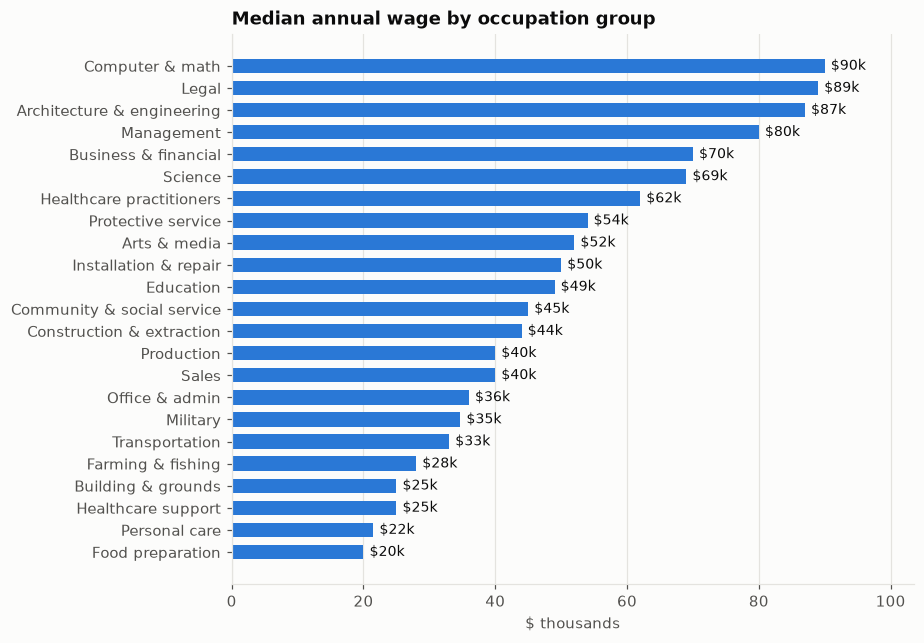

In [20]:
by_occ = sample.groupby("occupation").agg(median_wage=("wage", "median"), people=("wage", "size")).sort_values("median_wage")

fig, ax = plt.subplots(figsize=(8, 6.5))
ax.barh(by_occ.index, by_occ["median_wage"] / 1000, color=BLUE, height=0.65)
for y, v in enumerate(by_occ["median_wage"] / 1000):
    ax.annotate(f"${v:,.0f}k", (v, y), xytext=(4, 0), textcoords="offset points", va="center", color=INK, fontsize=9)
ax.set(title="Median annual wage by occupation group", xlabel=r"\$ thousands",
       xlim=(0, by_occ["median_wage"].max() / 1000 * 1.15))
ax.grid(axis="y", visible=False)
fig.savefig(FIG_DIR / "wage_by_occupation.png")
plt.show()

Occupation produces the widest spread in the data: a 4.5-fold difference in median wages between
computer and math occupations ($90k) and food preparation ($20k). High-paying occupations largely
require degrees, so occupation and education overlap heavily. This becomes visible in the
stepwise and importance results later.

### 5.6 Hours, weeks and wages

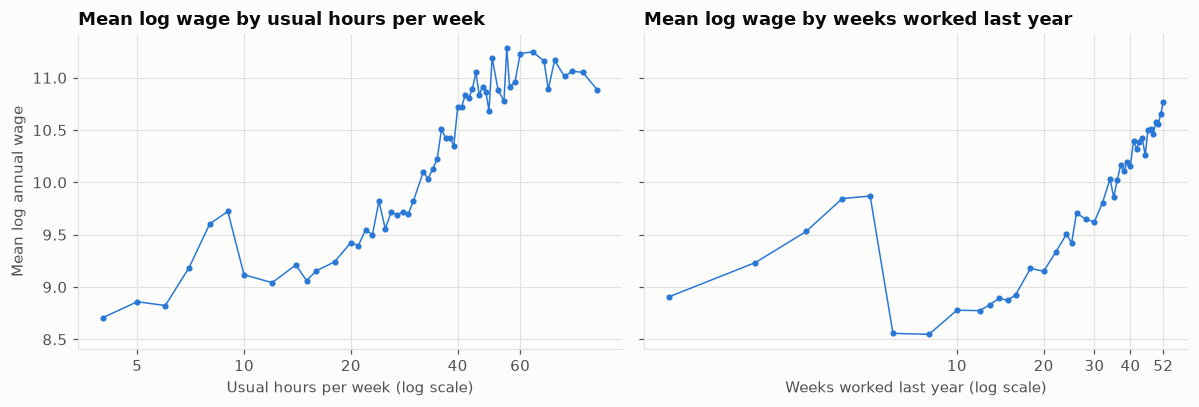

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, (col, label) in zip(axes, [("hours", "Usual hours per week"), ("weeks", "Weeks worked last year")]):
    grp = sample.groupby(col).apply(lambda g: pd.Series({"y": wmean(g[TARGET], g[WEIGHT]), "n": len(g)}),
                                    include_groups=False)
    grp = grp[grp["n"] >= 500]  # skip sparsely populated values
    ax.plot(np.log(grp.index), grp["y"], color=BLUE, marker="o", ms=3, lw=1)
    ticks = [5, 10, 20, 40, 60] if col == "hours" else [10, 20, 30, 40, 52]
    ax.set_xticks(np.log(ticks), ticks)
    ax.set(title=f"Mean log wage by {label.lower()}", xlabel=f"{label} (log scale)")
axes[0].set_ylabel("Mean log annual wage")
fig.tight_layout()
fig.savefig(FIG_DIR / "wage_hours_weeks.png")
plt.show()

- **Above about 10 hours a week and 10 weeks a year**, log wage rises almost linearly with log
  hours and log weeks, which supports entering both in logs. Wages plateau beyond about 60 hours.
- **Below that**, the relationship is erratic. Workers reporting only a few weeks show
  *higher* average wages than those reporting 8–9 weeks. This is consistent with measurement
  error in self-reported labor supply, which was especially likely in 2020, when many jobs were
  interrupted.

A linear model has to fit one slope through both regions. A tree-based model can treat the
low-hours and low-weeks region separately, one reason to expect the random forest to do better at
the bottom of the wage distribution.

## 6. Train/test design

A random 200,000 workers (about 23% of the sample) is drawn and split 80/20. Every tuning decision
uses the 160,000 training workers only: the Lasso and Ridge penalties, the stepwise model size,
and the random-forest settings. The 40,000 test workers are scored once at the end. The
subsample keeps the random forest and the stepwise search (several hundred regressions) fast
while leaving ample data for roughly 170 features.

Numeric features are standardized and categorical ones are one-hot encoded, with the first level
dropped. Standardizing matters for Lasso and Ridge, since the penalty is not scale-invariant.

In [22]:
train, test = train_test_split(sample.sample(200_000, random_state=SEED), test_size=0.2, random_state=SEED)
print(f"train: {len(train):,}   test: {len(test):,}")
print(f"Mean log wage - train: {wmean(train[TARGET], train[WEIGHT]):.3f}   test: {wmean(test[TARGET], test[WEIGHT]):.3f}")


def preprocessor(numeric=NUMERIC, categorical=CATEGORICAL):
    return ColumnTransformer([
        ("num", StandardScaler(), list(numeric)),
        ("cat", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False), list(categorical)),
    ])


def make_pipe(model, numeric=NUMERIC, categorical=CATEGORICAL):
    return Pipeline([("prep", preprocessor(numeric, categorical)), ("model", model)])


def fit(pipe, df):
    return pipe.fit(df, df[TARGET], model__sample_weight=df[WEIGHT])


def weighted_rmse(pipe, df):
    return np.sqrt(np.average((df[TARGET] - pipe.predict(df)) ** 2, weights=df[WEIGHT]))

train: 160,000   test: 40,000
Mean log wage - train: 10.644   test: 10.640


The train and test sets have the same mean log wage, so the split is representative.

## 7. Model 1: OLS with all features

$$
\log(\text{wage}_i) = \beta_0 + \beta_1\,\text{age}_i + \beta_2\,\text{age}_i^2 + \beta_3 \log(\text{hours}_i)
+ \beta_4 \log(\text{weeks}_i) + \sum_k \gamma_k\, D_{ik} + \varepsilon_i
$$

where the $D_{ik}$ are dummies for sex, marital status, race, Hispanic origin, nativity,
education, degree field, occupation, industry and state of work. With 160,000 observations and
about 170 parameters, overfitting is not a real risk, so OLS is a strong baseline.

In [23]:
ols = fit(make_pipe(LinearRegression()), train)
names = ols.named_steps["prep"].get_feature_names_out()
coef = pd.Series(ols.named_steps["model"].coef_, index=names)
print(f"Training R²: {1 - weighted_rmse(ols, train) ** 2 / np.cov(train[TARGET], aweights=train[WEIGHT]):.3f}")

# Labor-supply elasticities: numeric features are standardized, so divide by each feature's SD.
scaler = ols.named_steps["prep"].named_transformers_["num"]
elasticity = pd.Series(ols.named_steps["model"].coef_[:len(NUMERIC)] / scaler.scale_, index=NUMERIC)
print(f"Elasticity of annual wage w.r.t. hours: {elasticity['log_hours']:.2f}, weeks: {elasticity['log_weeks']:.2f}")

Training R²: 0.560
Elasticity of annual wage w.r.t. hours: 0.88, weeks: 0.43


In [24]:
# The encoder drops the alphabetically first level, so re-base education on "Less than high school".
# exp(b) - 1 converts a difference in log points into a percentage difference.
edu = pd.Series({lev: coef.get(f"cat__education_{lev}", 0.0) for _, lev in EDUCATION})
edu_premium = 100 * np.expm1(edu - edu["Less than high school"])
gender_gap = 100 * np.expm1(-coef["cat__sex_Male"])
print(f"Women earn {-gender_gap:.1f}% less than otherwise-identical men (same hours, weeks, job, education, ...)")
edu_premium.drop("Less than high school").map("{:+.0f}%".format).to_frame(
    "wage premium vs. less than high school")

Women earn 16.7% less than otherwise-identical men (same hours, weeks, job, education, ...)


,wage premium vs. less than high school
High school / GED,+12%
Some college,+19%
Associate,+24%
Bachelor's,+39%
Master's,+69%
Professional,+107%
Doctorate,+103%


**Interpretation.**
- **No overfitting.** Training R² (0.560) and test R² (0.558, below) are almost identical.
- **Labor supply.** A 1% increase in usual hours raises annual wages by 0.88%, and a 1% increase in
  weeks worked by 0.43%. Both elasticities are below 1, the value implied by a constant hourly
  wage, which is consistent with the measurement error seen in Section 5.6. Noisy regressors bias
  OLS slopes toward zero.
- **Education premia** rise steadily: +39% for a bachelor's degree and roughly +100% for a doctorate
  or professional degree, relative to no high-school diploma. These are much smaller than the raw
  gaps in Section 5.3 (a bachelor's median is 114% above the no-diploma median). Holding
  occupation and hours fixed removes the part of education's payoff that works through *which
  job* a graduate gets.
- **Gender.** Holding everything in the model equal, women earn **16.7% less** than men, against
  26% in the raw comparison. About a third of the raw gap is accounted for by differences in
  hours, weeks, occupation and industry. The rest is not explained by the variables available,
  which do not include experience, tenure or employer, so it should not be read as a measure of
  discrimination alone.

## 8. Model 2: forward stepwise selection

Forward selection adds one *feature group* at a time, choosing at each step the group that most
reduces 5-fold cross-validated RMSE on the training set. A whole group enters together (for
example, all occupation dummies), because adding individual dummies would produce an
uninterpretable model. The final size follows the **one-standard-error rule**: the smallest model
whose CV error is within one standard error of the best.

In [25]:
GROUPS = {"age": ["age", "age_sq"], "hours": ["log_hours"], "weeks": ["log_weeks"]} | {c: [c] for c in CATEGORICAL}
kf = KFold(5, shuffle=True, random_state=SEED)


def cv_rmse(groups):
    cols = [c for g in groups for c in GROUPS[g]]
    num, cat = [c for c in cols if c in NUMERIC], [c for c in cols if c in CATEGORICAL]
    errs = [weighted_rmse(fit(make_pipe(LinearRegression(), num, cat), train.iloc[tr]), train.iloc[va])
            for tr, va in kf.split(train)]
    return np.mean(errs), np.std(errs, ddof=1) / np.sqrt(len(errs))


chosen, remaining, path = [], list(GROUPS), []
while remaining:
    scores = {g: cv_rmse(chosen + [g]) for g in remaining}
    best = min(scores, key=lambda g: scores[g][0])
    chosen.append(best)
    remaining.remove(best)
    path.append({"step": len(chosen), "added": best, "cv_rmse": scores[best][0], "se": scores[best][1]})
path = pd.DataFrame(path).set_index("step")

threshold = path["cv_rmse"].min() + path.loc[path["cv_rmse"].idxmin(), "se"]
n_selected = path.index[path["cv_rmse"] <= threshold].min()
stepwise_groups = path.loc[:n_selected, "added"].tolist()
print(f"Selected {n_selected} of {len(GROUPS)} groups: {', '.join(stepwise_groups)}")
path

Selected 9 of 13 groups: occupation, hours, weeks, education, age, industry, work_state, sex, marital


,added,cv_rmse,se
step,,,
1,occupation,0.799,0.004
2,hours,0.718,0.004
3,weeks,0.685,0.004
4,education,0.656,0.004
5,age,0.632,0.005
6,industry,0.622,0.005
7,work_state,0.616,0.005
8,sex,0.610,0.005
9,marital,0.608,0.005


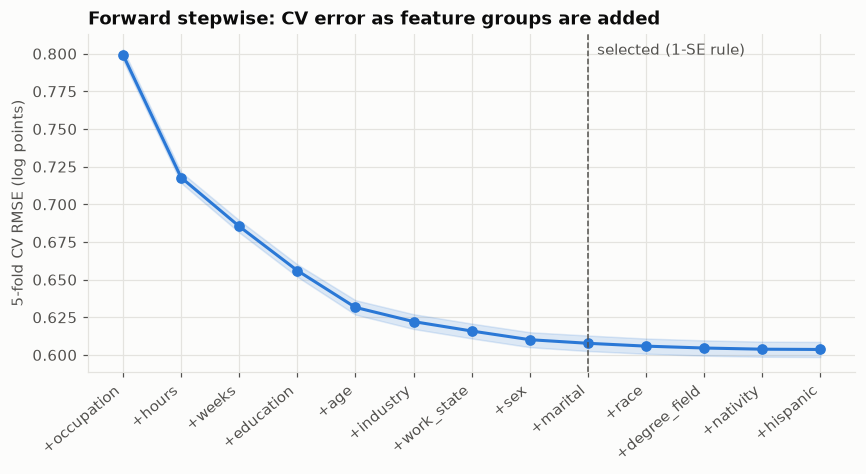

In [26]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(path.index, path["cv_rmse"], color=BLUE, lw=2, marker="o", ms=6)
ax.fill_between(path.index, path["cv_rmse"] - path["se"], path["cv_rmse"] + path["se"], color=BLUE, alpha=0.15)
ax.axvline(n_selected, color=INK_2, ls="--", lw=1)
ax.annotate("selected (1-SE rule)", (n_selected, path["cv_rmse"].max()), xytext=(6, 0),
            textcoords="offset points", color=INK_2)
ax.set_xticks(path.index, [f"+{g}" for g in path["added"]], rotation=40, ha="right")
ax.set(title="Forward stepwise: CV error as feature groups are added", ylabel="5-fold CV RMSE (log points)")
fig.savefig(FIG_DIR / "wage_stepwise_path.png")
plt.show()

**Interpretation.** Occupation enters first: on its own it explains more than any other group.
Hours and weeks follow, then education and age. The first five groups cut CV RMSE from 0.80 to
0.63. The next four (industry, state, sex, marital status) together lower it by only another
0.025, and the last four improve it by less than one standard error. The selected model keeps
nine groups.

## 9. Models 3–5: Lasso, Ridge and random forest

- **Lasso** (L1 penalty) shrinks coefficients and sets some exactly to zero. λ is chosen by 5-fold
  CV over 40 values.
- **Ridge** (L2 penalty) shrinks all coefficients toward zero without removing any. λ is chosen by
  efficient leave-one-out CV over 40 values.
- **Random forest**: 300 trees, each split considering 30% of features, with at least 20 workers
  per leaf. It can capture non-linearities and interactions, such as an education premium that
  differs by occupation, which the linear models cannot represent unless they are specified by
  hand.

In [27]:
stepwise_cols = [c for g in stepwise_groups for c in GROUPS[g]]
models = {
    "OLS (all features)": make_pipe(LinearRegression()),
    "Forward stepwise": make_pipe(LinearRegression(), [c for c in stepwise_cols if c in NUMERIC],
                                  [c for c in stepwise_cols if c in CATEGORICAL]),
    "Lasso (CV λ)": make_pipe(LassoCV(alphas=np.logspace(-6, 0, 40), cv=5, random_state=SEED,
                                      n_jobs=-1, max_iter=5000)),
    "Ridge (CV λ)": make_pipe(RidgeCV(alphas=np.logspace(-3, 5, 40), store_cv_results=True)),
    "Random forest": make_pipe(RandomForestRegressor(n_estimators=300, max_features=0.3, min_samples_leaf=20,
                                                     random_state=SEED, n_jobs=-1)),
}

rows, test_pred = [], {}
for name, pipe in models.items():
    fit(pipe, train)
    test_pred[name] = pipe.predict(test)
    resid = test[TARGET] - test_pred[name]
    tw = test[WEIGHT]
    mse = np.average(resid ** 2, weights=tw)
    rows.append({
        "model": name,
        "features": len(pipe.named_steps["prep"].get_feature_names_out()),
        "λ": getattr(pipe.named_steps["model"], "alpha_", np.nan),
        "test RMSE": np.sqrt(mse),
        "test MAE": np.average(np.abs(resid), weights=tw),
        "test R²": 1 - mse / np.average((test[TARGET] - wmean(test[TARGET], tw)) ** 2, weights=tw),
        "median |% error|": 100 * np.median(np.abs(np.expm1(-resid))),
    })
scores = pd.DataFrame(rows).set_index("model").sort_values("test RMSE")
scores.assign(**{"λ": scores["λ"].map(lambda v: "–" if np.isnan(v) else f"{v:.2g}"),
                 "median |% error|": scores["median |% error|"].map("{:.1f}%".format)})

,features,λ,test RMSE,test MAE,test R²,median |% error|
model,,,,,,
Random forest,154,–,0.579,0.420,0.595,30.0%
OLS (all features),154,–,0.605,0.436,0.558,30.9%
Ridge (CV λ),154,8.9e+02,0.605,0.436,0.558,30.9%
Lasso (CV λ),154,1.7e-05,0.605,0.436,0.558,30.9%
Forward stepwise,109,–,0.609,0.440,0.553,31.1%


### 9.1 Choosing λ for Lasso and Ridge

The CV curves show where each penalty trades bias for variance. Both are flat until λ becomes large.
With 160,000 observations and 154 features, the unpenalized model barely overfits, so CV chooses
almost no shrinkage. Ridge's λ ≈ 900 looks large, but scikit-learn applies the penalty against
the *weighted* sum of squared errors, and the person weights sum to roughly 20 million. In
relative terms the shrinkage is negligible. The Ridge axis is in the same weight-scaled units,
so only the shape of that curve matters.

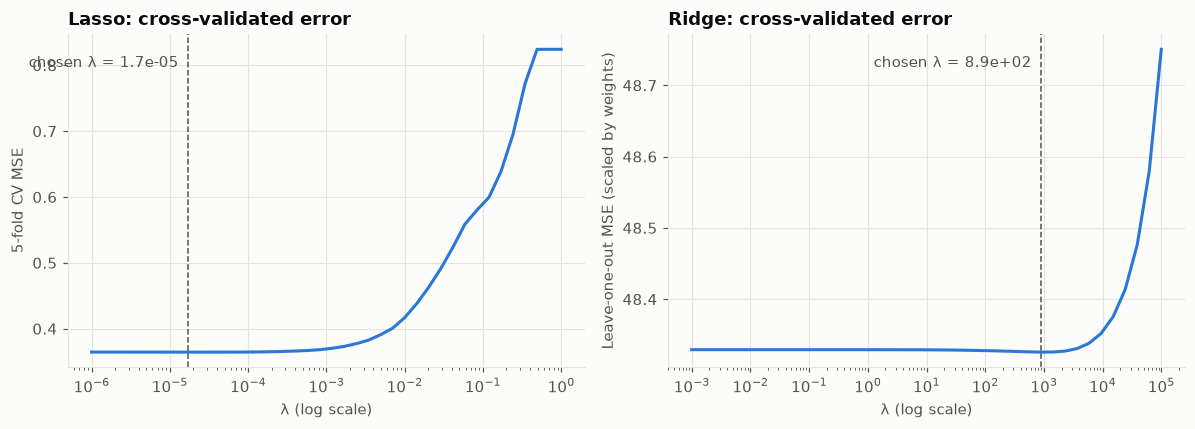

Lasso keeps 142 of 154 coefficients non-zero; dropped:
degree_field_11, degree_field_26, degree_field_38, degree_field_51, degree_field_54, degree_field_57, work_state_29, work_state_82, work_state_83, work_state_84, work_state_85, work_state_88


In [28]:
lasso = models["Lasso (CV λ)"].named_steps["model"]
ridge = models["Ridge (CV λ)"].named_steps["model"]
lasso_cv = pd.Series(lasso.mse_path_.mean(axis=1), index=lasso.alphas_)
ridge_cv = pd.Series(ridge.cv_results_.mean(axis=0), index=ridge.alphas)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (title, curve, best) in zip(axes, [("Lasso", lasso_cv, lasso.alpha_), ("Ridge", ridge_cv, ridge.alpha_)]):
    ax.plot(curve.index, curve.values, color=BLUE, lw=2)
    ax.axvline(best, color=INK_2, ls="--", lw=1)
    ax.annotate(f"chosen λ = {best:.2g}", (best, curve.max()), xytext=(-6, -4), textcoords="offset points",
                va="top", ha="right", color=INK_2)
    ax.set(xscale="log", title=f"{title}: cross-validated error", xlabel="λ (log scale)")
axes[0].set_ylabel("5-fold CV MSE")
axes[1].set_ylabel("Leave-one-out MSE (scaled by weights)")
fig.tight_layout()
fig.savefig(FIG_DIR / "wage_lambda_paths.png")
plt.show()

lasso_coef = pd.Series(lasso.coef_, index=names)
print(f"Lasso keeps {np.sum(lasso.coef_ != 0)} of {lasso.coef_.size} coefficients non-zero; dropped:")
print(", ".join(lasso_coef[lasso_coef == 0].index.str.replace("cat__", "")))

Lasso removes only 12 of 154 dummies: six fields of degree and six place-of-work codes. These are
small categories whose wages do not differ detectably from the reference group. Everything else
survives. The Lasso solution is essentially OLS, and so are its predictions.

### 9.2 Model comparison

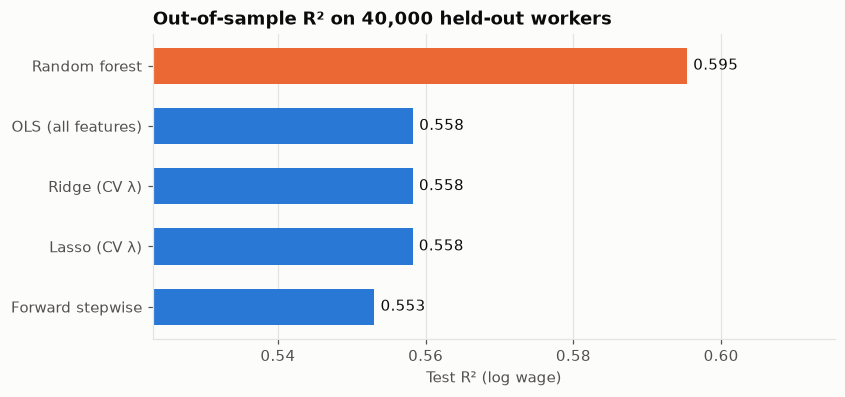

In [29]:
fig, ax = plt.subplots(figsize=(8, 3.6))
s = scores["test R²"].sort_values()
ax.barh(s.index, s, color=[ORANGE if n == "Random forest" else BLUE for n in s.index], height=0.6)
for y, v in enumerate(s):
    ax.annotate(f"{v:.3f}", (v, y), xytext=(4, 0), textcoords="offset points", va="center", color=INK)
ax.set(title="Out-of-sample R² on 40,000 held-out workers", xlabel="Test R² (log wage)",
       xlim=(s.min() - 0.03, s.max() + 0.02))
ax.grid(axis="y", visible=False)
fig.savefig(FIG_DIR / "wage_model_comparison.png")
plt.show()

### 9.3 Where does the random forest gain?

Compare the prediction errors of OLS and the random forest across the distribution of actual
wages, using test-set deciles.

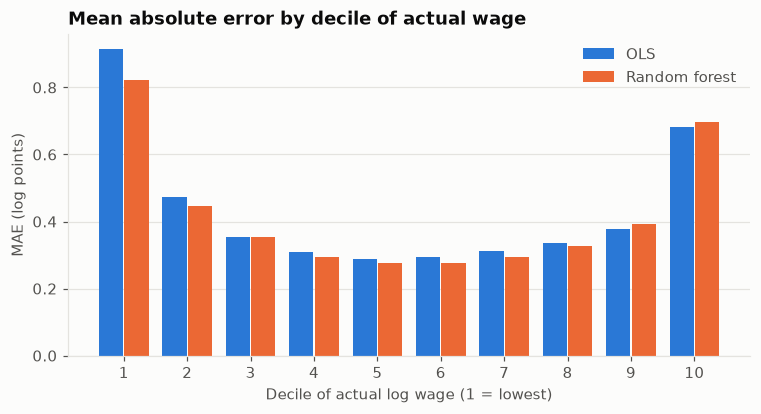

log_wage,1,2,3,4,5,6,7,8,9,10
OLS (all features),0.914,0.474,0.353,0.309,0.289,0.295,0.313,0.335,0.378,0.681
Random forest,0.821,0.448,0.353,0.293,0.276,0.276,0.295,0.327,0.392,0.697


In [30]:
decile = pd.qcut(test[TARGET], 10, labels=range(1, 11))
err = pd.DataFrame({name: (test[TARGET] - test_pred[name]).abs() for name in ["OLS (all features)", "Random forest"]})
by_decile = err.groupby(decile, observed=True).mean()

fig, ax = plt.subplots(figsize=(8, 3.8))
x = np.arange(1, 11)
ax.bar(x - 0.2, by_decile["OLS (all features)"], width=0.38, color=BLUE, label="OLS")
ax.bar(x + 0.2, by_decile["Random forest"], width=0.38, color=ORANGE, label="Random forest")
ax.set(title="Mean absolute error by decile of actual wage", xlabel="Decile of actual log wage (1 = lowest)",
       ylabel="MAE (log points)", xticks=x)
ax.legend(frameon=False, labelcolor=INK_2)
ax.grid(axis="x", visible=False)
fig.savefig(FIG_DIR / "wage_error_by_decile.png")
plt.show()
by_decile.T.round(3)

- **Both models struggle at the extremes.** Errors are U-shaped across deciles: about 0.9 log points
  in the bottom decile, where very low annual earnings come from part-year work, and about 0.7 in
  the top decile, where top-coding applies and pay depends on things the survey does not measure.
- **The random forest's advantage is concentrated at the bottom.** In the lowest decile it cuts the
  error from 0.91 to 0.82, and it is slightly better through the middle deciles. This is the
  irregular low-hours and low-weeks region from Section 5.6, which a single linear slope cannot
  fit.
- **It is slightly worse in the top two deciles.** Each tree leaf averages at least 20 workers, so
  the forest shrinks extreme predictions toward the middle. Overall the trade favours the forest,
  because the gains at the bottom are larger.

## 10. What drives the predictions?

Permutation importance measures how much the random forest's test R² falls when one variable's
values are shuffled, breaking its link to wages. Shuffling is done on the original variable, not
on individual dummies, so the scores can be compared across variables with different numbers of
categories. This method avoids the known bias of impurity-based importance toward
high-cardinality features.

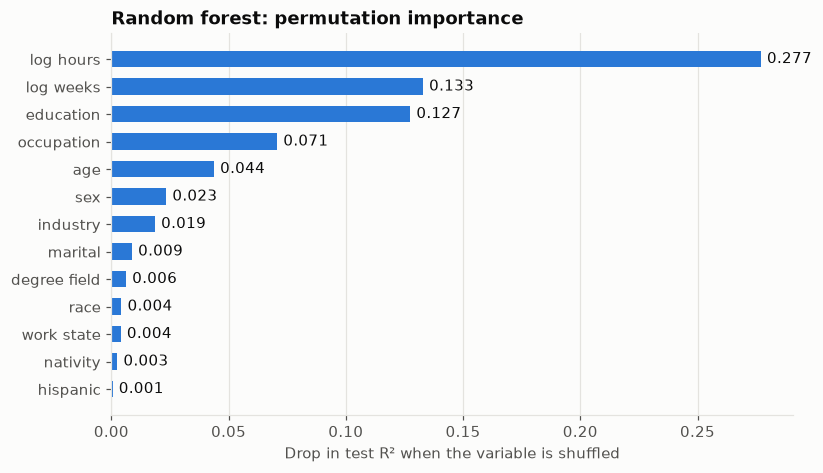

In [31]:
rf = models["Random forest"]
sub = test.sample(10_000, random_state=SEED)
features = NUMERIC + CATEGORICAL
perm = permutation_importance(rf, sub[features], sub[TARGET], sample_weight=sub[WEIGHT], n_repeats=5,
                              scoring="r2", random_state=SEED, n_jobs=-1)
importance = pd.Series(perm.importances_mean, index=features)
importance["age"] += importance.pop("age_sq")
importance = importance.sort_values()

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(importance.index.str.replace("_", " "), importance, color=BLUE, height=0.6)
for y, v in enumerate(importance):
    ax.annotate(f"{v:.3f}", (v, y), xytext=(4, 0), textcoords="offset points", va="center", color=INK)
ax.set(title="Random forest: permutation importance", xlabel="Drop in test R² when the variable is shuffled")
ax.grid(axis="y", visible=False)
fig.savefig(FIG_DIR / "wage_permutation_importance.png")
plt.show()

**Interpretation.** Hours worked is by far the most important input: shuffling it costs 0.28 of
R², about half of the model's total explanatory power. Weeks worked and education follow at about
0.13 each, then occupation and age. Occupation enters the stepwise model first but ranks fourth
here, because once the forest knows education and hours, occupation adds less on its own.
Demographic variables (race, nativity, Hispanic origin) each contribute less than 0.005. They
matter little for *prediction* once job and labor-supply variables are known, even where their
coefficients in OLS are statistically significant.

## 11. Conclusions

| | Test R² | Test RMSE | Notes |
|---|---|---|---|
| Random forest | **0.595** | **0.579** | Best on every metric |
| OLS / Lasso / Ridge | 0.558 | 0.605 | Indistinguishable; CV picks almost no penalty |
| Forward stepwise | 0.553 | 0.609 | 9 of 13 feature groups, 109 instead of 154 coefficients |

**Differences between the approaches.**
- **OLS** is already a strong model here. The sample is large relative to the number of
  parameters, so the variance that regularization is meant to control is small.
- **Lasso and Ridge** confirm this. Their cross-validated penalties are close to zero, and their
  predictions match OLS to three decimals. Shrinkage helps when *p* is large relative to *n* or
  predictors are highly collinear, and neither applies.
- **Forward stepwise** shows how quickly returns diminish, and gives the most parsimonious linear
  model at a small cost in accuracy.
- **The random forest** gains 3.7 points of R² because wages are not additive in logs: the return
  to hours and the education premium vary across occupations. A linear model captures these
  interactions only if each one is specified by hand.

**Best model.** For *prediction*, the random forest is best: it has the lowest error on held-out
data on every metric. For *explanation*, OLS remains valuable. It is nearly as accurate, and its
coefficients have a direct reading, such as the education premia and the gender gap. Most applied
work would report both.

**Limitations.** About 40% of the variation in log wages remains unexplained. Key drivers such as
ability, tenure, employer and firm size are not in the ACS. `INCWAGE` is top-coded for the
highest earners in each state, and annual wages for 2020 were affected by the pandemic in ways the
weights only partly correct. The importance scores describe what the model relies on, not causal
effects.